In [1]:
#Algorithum LSTM(Long - short Term Memory)
# yfinance    -> downloading the data set
# pandas      -> data manipulation
# numpy       -> mathematical calculations
# matplotlib  -> graphical representation
# tensorflow   -> LSTM neural network
# sklearn      -> scaling and model evaluation

In [2]:
# Import required libraries
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [3]:
# Download the dataset
data = yf.download("RELIANCE.NS", start="2020-01-01", end="2025-01-01",
                   auto_adjust=True)


[*********************100%***********************]  1 of 1 completed


In [4]:
# Clean and select the closing-price series
close_prices = data["Close"]
if isinstance(close_prices, pd.DataFrame):
    close_prices = close_prices.iloc[:, 0]

close_prices = close_prices.asfreq("B").ffill().dropna()

print(close_prices.head())
print("Records:", len(close_prices))


Date
2020-01-01    672.216187
2020-01-02    683.660278
2020-01-03    684.484131
2020-01-06    668.609375
2020-01-07    678.895630
Freq: B, Name: RELIANCE.NS, dtype: float64
Records: 1305


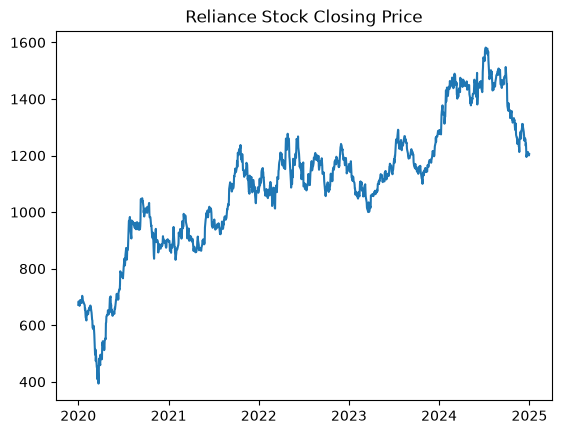

In [5]:
# Visualize the stock price trend
plt.plot(close_prices)
plt.title("Reliance Stock Closing Price")
plt.show()

In [6]:
# Print the raw downloaded data
print(data)


Price             Close         High          Low         Open      Volume
Ticker      RELIANCE.NS  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS RELIANCE.NS
Date                                                                      
2020-01-01   672.216187   680.008852   670.390532   675.956671    14004468
2020-01-02   683.660278   686.176208   673.284921   673.284921    17710316
2020-01-03   684.484131   686.487957   678.183188   682.636123    20984698
2020-01-06   668.609375   680.365106   667.050830   676.847322    24519177
2020-01-07   678.895630   683.304036   673.952826   676.401934    16683622
...                 ...          ...          ...          ...         ...
2024-12-24  1212.280762  1222.988340  1210.545745  1211.834663     6734917
2024-12-26  1206.133911  1217.188348  1203.853555  1213.767935    10016178
2024-12-27  1210.595459  1217.386785  1206.580087  1207.869004     7000397
2024-12-30  1200.333984  1212.726960  1197.756270  1205.985254     8818766
2024-12-31  1205.043213  

In [7]:
# Show the first rows of the raw data
data.head()


Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2020-01-01,672.216187,680.008852,670.390532,675.956671,14004468
2020-01-02,683.660278,686.176208,673.284921,673.284921,17710316
2020-01-03,684.484131,686.487957,678.183188,682.636123,20984698
2020-01-06,668.609375,680.365106,667.050830,676.847322,24519177
2020-01-07,678.895630,683.304036,673.952826,676.401934,16683622


In [8]:
# Show the last rows of the raw data
data.tail()


Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2024-12-24,1212.280762,1222.988340,1210.545745,1211.834663,6734917
2024-12-26,1206.133911,1217.188348,1203.853555,1213.767935,10016178
2024-12-27,1210.595459,1217.386785,1206.580087,1207.869004,7000397
2024-12-30,1200.333984,1212.726960,1197.756270,1205.985254,8818766
2024-12-31,1205.043213,1208.661986,1195.822913,1197.657049,6405475


In [9]:
# Inspect the dataset structure
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1238 entries, 2020-01-01 to 2024-12-31
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   (Close, RELIANCE.NS)   1238 non-null   float64
 1   (High, RELIANCE.NS)    1238 non-null   float64
 2   (Low, RELIANCE.NS)     1238 non-null   float64
 3   (Open, RELIANCE.NS)    1238 non-null   float64
 4   (Volume, RELIANCE.NS)  1238 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 90.3 KB


In [10]:
# Show the dataset dimensions
data.shape

(1238, 5)

In [11]:
# Split data and scale for LSTM
train_size = int(len(close_prices) * 0.8)
train = close_prices.iloc[:train_size]
test = close_prices.iloc[train_size:]

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1))
test_scaled = scaler.transform(test.to_numpy().reshape(-1, 1))


In [12]:
# Create lookback sequences
lookback = 60

def create_sequences(values):
    X, y = [], []
    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i, 0])
        y.append(values[i, 0])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled)


In [13]:
# Prepare test sequences using the last 60 days as context
context = np.concatenate([train_scaled[-lookback:], test_scaled])
X_test, y_test = create_sequences(context)

X_train = X_train.reshape(-1, lookback, 1)
X_test = X_test.reshape(-1, lookback, 1)


In [14]:
# Build the LSTM model
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(lookback, 1)),
    Dropout(0.2),
    LSTM(50),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer="adam", loss="mean_squared_error")


C:\Users\nvnat\lstm_env\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 14s 149ms/step - loss: 0.0735 - val_loss: 0.0016
Epoch 2/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - loss: 0.0100 - val_loss: 0.0011
Epoch 3/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step - loss: 0.0076 - val_loss: 0.0019
Epoch 4/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - loss: 0.0067 - val_loss: 0.0017
Epoch 5/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - loss: 0.0057 - val_loss: 8.6492e-04
Epoch 6/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - loss: 0.0059 - val_loss: 0.0015
Epoch 7/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - loss: 0.0054 - val_loss: 0.0018
Epoch 8/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - loss: 0.0057 - val_loss: 0.0012
Epoch 9/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - loss: 0.0051 - val_loss: 8.5108e-04
Epoch 10/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0052 - val_loss: 0.0011
Epoch 11/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0055 - val_loss: 0.0017
Epoch 12/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms

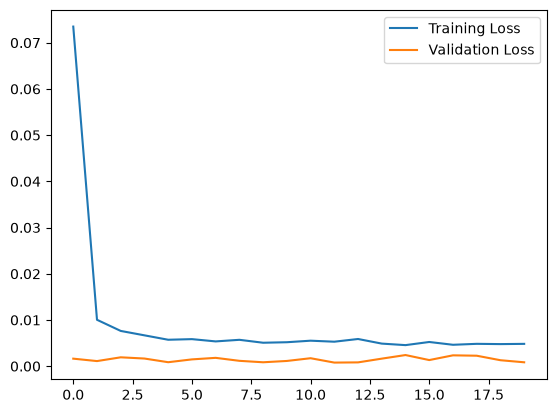

In [15]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1
)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.show()

In [16]:
# Predict on the test set and calculate error
predictions_scaled = model.predict(X_test, verbose=0)

predictions = scaler.inverse_transform(predictions_scaled).flatten()
actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

rmse = np.sqrt(mean_squared_error(actual, predictions))
print("RMSE =", rmse)


RMSE = 35.652026344392155


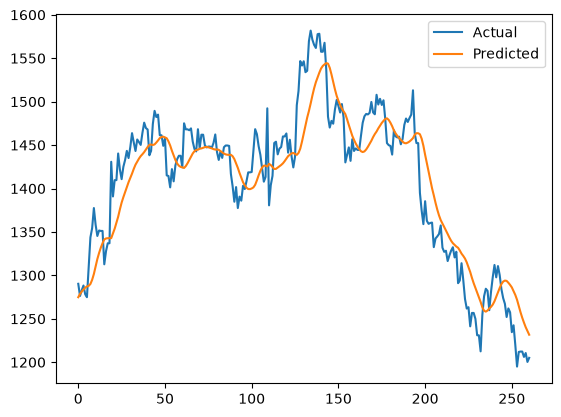

In [17]:
# Plot actual vs predicted prices
plt.plot(actual, label="Actual")
plt.plot(predictions, label="Predicted")
plt.legend()
plt.show()

In [18]:
# Forecast the next 30 trading days
future_steps = 30
history_window = train_scaled.tolist() + test_scaled.tolist()
future_scaled = []

for _ in range(future_steps):
    x = np.array(history_window[-lookback:]).reshape(1, lookback, 1)
    next_price = model.predict(x, verbose=0)[0, 0]
    future_scaled.append(next_price)
    history_window.append([next_price])


In [19]:
# Convert forecast back to original scale
future_prices = scaler.inverse_transform(
    np.array(future_scaled).reshape(-1, 1)
).flatten()

future_dates = pd.bdate_range(
    start=close_prices.index[-1] + pd.offsets.BDay(1),
    periods=future_steps
)

future = pd.Series(future_prices, index=future_dates)
print(future)


2025-01-01    1228.104614
2025-01-02    1226.490845
2025-01-03    1226.034424
2025-01-06    1226.316772
2025-01-07    1227.075439
2025-01-08    1228.144409
2025-01-09    1229.417480
2025-01-10    1230.826294
2025-01-13    1232.325195
2025-01-14    1233.884033
2025-01-15    1235.481812
2025-01-16    1237.103760
2025-01-17    1238.739868
2025-01-20    1240.382324
2025-01-21    1242.025146
2025-01-22    1243.664551
2025-01-23    1245.297241
2025-01-24    1246.920654
2025-01-27    1248.532837
2025-01-28    1250.132812
2025-01-29    1251.718872
2025-01-30    1253.290283
2025-01-31    1254.846558
2025-02-03    1256.387329
2025-02-04    1257.911987
2025-02-05    1259.420166
2025-02-06    1260.911499
2025-02-07    1262.386475
2025-02-10    1263.844727
2025-02-11    1265.286133
Freq: B, dtype: float32


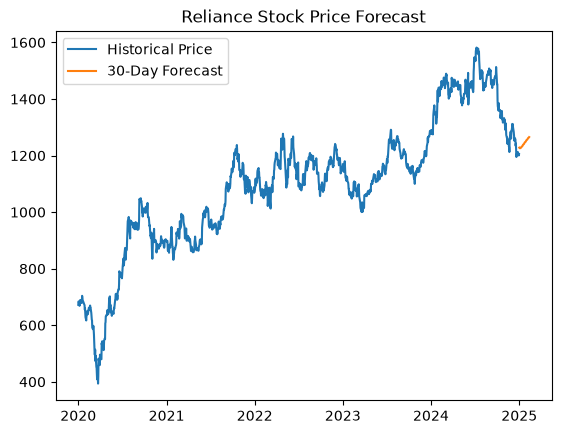

In [24]:
# Plot historical and forecasted prices
plt.plot(close_prices, label="Historical Price")
plt.plot(future, label="30-Day Forecast")
plt.legend()
plt.title("Reliance Stock Price Forecast")
#cell 20 - Output
plt.show()